# Download data 

In [2]:
import pyprojroot
import os
from pathlib import Path
import sys
import json
import requests
import zipfile,  io
#import geojson 

In [22]:
import geopandas as gpd

In [127]:
import pandas as pd
import re
import numpy as np

In [4]:
repodir = pyprojroot.find_root(pyprojroot.has_dir(".git"))
sys.path.append(str(repodir))

In [5]:
output_dir = repodir / 'gisdata' / 'NSW'

## Data download fro NSW SEED portal

### Load functions

Load this function in the local lib folder

In [6]:
from lib.seed.seed_metadata import md_download, md_desc

### Query metadata

In [9]:
md_id = '1d05e145-80cb-4275-af9b-327a1536798d'
md_url = 'https://datasets.seed.nsw.gov.au/api/3/action/package_show?id=' + md_id
firehistory_md=md_download(md_url)
md_desc(firehistory_md)

Metadata successfully downloaded


**title**

NPWS Fire History - Wildfires and Prescribed Burns



**lineage**

The data is generally captured from hardcopy 1:25,000 topographic maps (screen or tablet digitised), GPS or by remote sensing. Many of the NPWS polygons are generated through actual incident or prescribed burn mapping. The day to day progression of the fire is recorded and archived in the Fire Mapping structure (now using MapDesk under P:\Work\Fires) and the final fire boundary is transferred to the Fire GDB.  Historically the final shapefile was created via a "Dissolve" in ArcView. At times the final boundary is flown and captured by a GPS or hand drawn map and digitised back at the office. Fire history is also obtained from other agencies at the end of each fire season and integrated with our data. Often there are overlaps so that some decision is needed in retaining the most accurate, detailed fire boundaries. There are also various fire research projects using, for example, historical Landsat imagery which add further information to the fire history feature class.

Coded Domain Labels:
dmvFireType:
1       Wildfire
2       Prescribed Burn

1dmvCaptureMethod:
1	Dummy Geometry
2	Eye-ball Estimate
3	Digitised - On Screen
4	Digitised - Table
5	Scan/Vectorised
6	GPS
7	GPS - Differential
8	Survey
9	Stereo Image Trace
10	Aggregated GIS Data
11	Derived
9990	Other
9999	Unknown
dmvCaptureSource:
2	DECCW HHIMS/AHIMS Capture;
3	DECCW Data Other;
4	DECCW FAR Migration;
5	DECCW AMS Migration;
6	Marine Park Authority;
7	CRA Mapping;
8	Whereis;
9	Gregorys;
10	UBD;
11	Sydway;
12	Penguin Road Atlas;
13	RFS;
14	LPI DTDB;
15	LPI DCDB;
16	LPI Original 1:50k;
17	LPI Original 1:100k;
18	LPI Western Division;
19	Forests NSW;
20	NSW Agriculture;
21	RTA;
22	RIC;
23	NSW Fisheries;
24	DNR;
25	ACT Govt;
26	QLD Govt;
27	SA Govt;
28	Vic Govt;
29	D Defence;
30	Local Government;
9990	Other;
9999	Unknown;

1	DECCW Field Data Capture;

dmvCauseWildfire:;
1	Arson;
2	Arson Suspected;
3	Burning Off - Illegal;
4	Burning Off - Legal;
5	Camp Cooker/Camp Fire;
6	Lightning;
9999	Undetermined;
8	Motor Vehicle;
9	Power Lines;
10	Miscellaneous Known;
7	Machinery/Slasher;

dmvClassPrescribedBurn:;
1	Fuel Management;
2	Biodiversity;
3	Unknown;

dmvClassWildfire:;
1	Class 1;
2	Class 2;
3	Class 3;

dmvIntensity:;
9999	Unknown;
10	Surface and near surface fuels consumed;
20	Elevated fuels consumed (no canopy scorch);
30	Elevated fuels consumed (canopy scorch);
40	Canopy leaves consumed;
50	Canopy leaves and limbs consumed;
60	Entire canopy and part stems consumed



**Show on SEED Web Map**: Display dataset on SEED's map -- [SEED Web Map](https://geo.seed.nsw.gov.au/vertigisstudio/web/?app=cabd04d595ec43c1aaf4298e80e83ec2&workflow=36ea26c1-e8e2-4355-8600-5d1558259ad3&workflowParams={"portalItems": [{"itemId": "221ece6f68ba458099ad6329db4521a6", "layerIds": "0"}]})

**Data Quality Statement**: Data quality statement for NPWS Fire History - Wildfires and Prescribed Burns -- [PDF](https://datasets.seed.nsw.gov.au/dataset/fire-history-wildfires-and-prescribed-burns-1e8b6/resource/data_quality_report/pdf)

**Web Map Service (WMS)**: Connect to Web Map Service (view in GIS) -- [WMS](https://mapprod3.environment.nsw.gov.au/arcgis/rest/services/Fire/NPWS_Fire_History/MapServer)

**Download Package**: Data (Shapefile) -- [ZIP](https://datasets.seed.nsw.gov.au/dataset/1d05e145-80cb-4275-af9b-327a1536798d/resource/3853d6c0-6517-4cba-8482-68f93a6d43b1/download/fire_npwsfirehistory.zip)

In [10]:
md_id = 'c2066854-f228-4e16-b0d2-75e2168f7131'
md_url = 'https://datasets.seed.nsw.gov.au/api/3/action/package_show?id=' + md_id
TEC_md=md_download(md_url)
md_desc(TEC_md)

Metadata successfully downloaded


**title**

Threatened Ecological Communities Greater Sydney



**lineage**

Incorporates multiple sources of data. Compiled data then edited to incorporate expert input. Methodology documented in report. 



**Show on SEED Web Map**: Display dataset on SEED's map -- [SEED Web Map](https://geo.seed.nsw.gov.au/vertigisstudio/web/?app=cabd04d595ec43c1aaf4298e80e83ec2&workflow=36ea26c1-e8e2-4355-8600-5d1558259ad3&workflowParams={"portalItems": [{"itemId": "9b279774c1454cf7b9d252b8e9e92b25", "layerIds": "0"}]})

**Data Quality Statement**: Data quality statement for Threatened ecological communities Greater Sydney -- [PDF](https://datasets.seed.nsw.gov.au/dataset/threatened-ecological-communities-greater-sydney/resource/data_quality_report/pdf)

**Map of threatened ecological communities in Greater Sydney**: Report summarising the map compilation process and updates. -- [PDF](https://datasets.seed.nsw.gov.au/dataset/c2066854-f228-4e16-b0d2-75e2168f7131/resource/2f2c487a-b457-4207-a036-27ae0601a694/download/map-of-threatened-ecological-communities-in-greater-sydney.pdf)

**ArcGIS REST Service - Threatened Ecological Communities Greater Sydney**: An ArcGIS Server web service represents a GIS resource—such as a map, locator, or image—that is located on an ArcGIS Server site and is made available to client applications.

Depending on the layers enabled, this web service allows a user to query its features and/or visualise the dataset.

This service is aimed at advanced geographical information users, and will require access to geographical information system (GIS) software such as ArcGIS/ArcMap. -- [ARCGIS REST SERVICE](https://mapprod1.environment.nsw.gov.au/arcgis/rest/services/EDP/TECs_GreaterSydney/MapServer)

**WMS - Threatened Ecological Communities Greater Sydney**: Web Map Service (WMS) is a standard protocol for serving georeferenced map images over the internet that are generated by a map server using data from a GIS Database (NSW Government - Spatial Web Services Register June 2015).

WMS allows a user to spatially visualise the dataset, but not query its features.

This service is aimed at advanced geographical information users, and will require access to geographical information system (GIS) software such as QGIS and ArcGIS/ArcMap. -- [WMS](https://mapprod1.environment.nsw.gov.au/arcgis/services/EDP/TECs_GreaterSydney/MapServer/WMSServer?request=GetCapabilities&service=WMS)

**Threatened ecological communities Greater Sydney**: 2024 shapefile and layer file, and 2021 report. -- [ZIP](https://datasets.seed.nsw.gov.au/dataset/c2066854-f228-4e16-b0d2-75e2168f7131/resource/4998a651-9da1-4112-84e6-013aab30ab88/download/vegetation_tec_greater_sydney_2024.zip)

### download GIS data

In [11]:
zip_url = TEC_md['result']['resources'][5]['url']

In [12]:
r = requests.get(zip_url)
z = zipfile.ZipFile(io.BytesIO(r.content))

In [13]:
for j in z.namelist():
    print(j)

Map of threatened ecological communities in Greater Sydney.pdf
Threatened_ecological_communities_GreaterSydney_2024.cpg
Threatened_ecological_communities_GreaterSydney_2024.dbf
Threatened_ecological_communities_GreaterSydney_2024.lyr
Threatened_ecological_communities_GreaterSydney_2024.prj
Threatened_ecological_communities_GreaterSydney_2024.sbn
Threatened_ecological_communities_GreaterSydney_2024.sbx
Threatened_ecological_communities_GreaterSydney_2024.shp
Threatened_ecological_communities_GreaterSydney_2024.shp.xml
Threatened_ecological_communities_GreaterSydney_2024.shx


We can download a copy of these, with this code:

In [14]:
output_dir.mkdir(parents=True, exist_ok=True)
z.extractall(output_dir)
z.close()

In [17]:
zip_url = firehistory_md['result']['resources'][3]['url']

In [18]:
r = requests.get(zip_url)
z = zipfile.ZipFile(io.BytesIO(r.content))

In [19]:
for j in z.namelist():
    print(j)

NPWSFireHistory.cpg
NPWSFireHistory.dbf
NPWSFireHistory.prj
NPWSFireHistory.sbn
NPWSFireHistory.sbx
NPWSFireHistory.shp
NPWSFireHistory.shp.xml
NPWSFireHistory.shx


In [20]:
output_dir.mkdir(parents=True, exist_ok=True)
z.extractall(output_dir)
z.close()

## Load GIS data

In [24]:
firehistory = gpd.read_file(output_dir / "NPWSFireHistory.shp")

In [36]:
firehistory.head()

,FireType,FireName,FireNo,Label,StartDate,EndDate,AreaHa,PerimeterM,d_FireType,geometry
0,2,None,None,1970-71 Prescribed Burn,NaT,NaT,299.985464,8615.637120,Prescribed Burn,"POLYGON ((152.77796 -31.63806, 152.77822 -31.6..."
1,2,None,70/161,1970-71 Prescribed Burn,NaT,NaT,309.025645,20657.633993,Prescribed Burn,"POLYGON ((151.50894 -31.98245, 151.50911 -31.9..."
2,2,None,None,1970-71 Prescribed Burn,1970-07-01,NaT,13.600002,1999.487701,Prescribed Burn,"POLYGON ((153.14728 -30.17573, 153.14721 -30.1..."
3,2,None,0,1971-72 Prescribed Burn,1971-07-01,NaT,58.994371,5312.210152,Prescribed Burn,"POLYGON ((152.2127 -32.24101, 152.21272 -32.24..."
4,2,None,0,1971-72 Prescribed Burn,1971-07-01,NaT,383.155154,20564.602731,Prescribed Burn,"POLYGON ((152.1928 -32.2418, 152.19281 -32.241..."


In [25]:
TECdist = gpd.read_file(output_dir / "Threatened_ecological_communities_GreaterSydney_2024.shp")

In [31]:
TECdist.groupby('POTENTIAL_').agg({'Shape_Area':{'count','sum'}})

Shape_Area       
                  sum  count
POTENTIAL_                  
TEC_ABW      0.000161     29
TEC_BGHF     0.000773   1832
TEC_BMBF     0.004321    549
TEC_BMSCF    0.000099     28
TEC_BMSw     0.003103   1885
TEC_BSF      0.000022     20
TEC_CPW      0.021418  12412
TEC_CRCIF    0.004934   1541
TEC_CSGW     0.003736    815
TEC_CSW      0.000540    204
TEC_CSm      0.000294   1058
TEC_CUS      0.001284   1117
TEC_DFEC     0.000389    339
TEC_EBSF     0.000013     38
TEC_ESBS     0.000499    458
TEC_FWCF     0.001065    353
TEC_HC       0.000018      2
TEC_KDF      0.000096     76
TEC_LR       0.000092    102
TEC_MPS      0.000144     47
TEC_MSSF     0.000004      1
TEC_MSW      0.001323    853
TEC_OCSF     0.000063     13
TEC_PWSGF    0.000481    215
TEC_RFEFCF   0.010925   4887
TEC_SFW      0.000123    217
TEC_SOFF     0.000887   1622
TEC_SSFCF    0.000399    285
TEC_SSSF     0.000181     30
TEC_SSTF     0.019509   6685
TEC_STIF     0.003135   3632
TEC_SVCGF    0.000040     87
TEC_TGSCH    0.000014     33
TEC_TSC      0.000044      1
TEC_WSDR     0.000563    607

This is the plan
- [x] select ESBS polygons
- [x] select random points inside polygons (1, 5, 10 per polygon)
- [x] intersect points with firehistory
- aggregate by points and calculate number of fires, earliests and latest fire year
- histograms of these
- for each point use a random sampling date, calculate intervals from last fire and penultimate fire
- histograms of these

In [87]:
pts01 = TECdist.loc[TECdist.POTENTIAL_=="TEC_ESBS"].sample_points(size=1)
pts05 = TECdist.loc[TECdist.POTENTIAL_=="TEC_ESBS"].sample_points(size=5)
pts10 = TECdist.loc[TECdist.POTENTIAL_=="TEC_ESBS"].sample_points(size=10)

In [97]:
fh_ESBS_01 = gpd.sjoin(gpd.GeoDataFrame(geometry=pts01, crs= TECdist.crs),
          firehistory,
          predicate='intersects',
                   how='left')

In [168]:
minyear =  list()
maxyear =  list()
for idx, row in fh_ESBS_01.iterrows():
    if row.StartDate != row.StartDate:
        if row.Label != row.Label:
            minyear.append(None)
        else:
            minyear.append(int(re.findall(r'\d+', row.Label)[0]))
    else:
        minyear.append(row.StartDate.year)
for idx, row in fh_ESBS_01.iterrows():
    if row.EndDate != row.StartDate:
        if row.Label != row.Label:
            maxyear.append(None)
        else:
            maxyear.append(int(re.findall(r'\d+', row.Label)[0]))
    else:
        maxyear.append(row.EndDate.year)


In [169]:
fh_ESBS_01['MinYear'] = minyear
fh_ESBS_01['MaxYear'] = maxyear

In [170]:
aggfuncs = {'index_right': 'count', 'Label':'count', 'MinYear': 'min', 'MaxYear': 'max'}
fh_agg_01 = fh_ESBS_01.groupby(level=0).agg(aggfuncs)

In [171]:
fh_agg_01

,index_right,Label,MinYear,MaxYear
16569,2,2,2000.0,2017.0
16570,2,2,2000.0,2017.0
16571,0,0,NaN,NaN
16572,0,0,NaN,NaN
16573,0,0,NaN,NaN
...,...,...,...,...
38541,2,2,1995.0,2015.0
38542,0,0,NaN,NaN
38543,2,2,1982.0,2000.0
39603,0,0,NaN,NaN


In [172]:

from matplotlib import pyplot as plt

In [173]:
counts, bins = np.histogram(fh_agg_01.index_right)

(array([285.,  67.,   0.,  56.,   0.,  21.,  20.,   0.,   8.,   1.]),
 array([0. , 0.6, 1.2, 1.8, 2.4, 3. , 3.6, 4.2, 4.8, 5.4, 6. ]),
 <BarContainer object of 10 artists>)

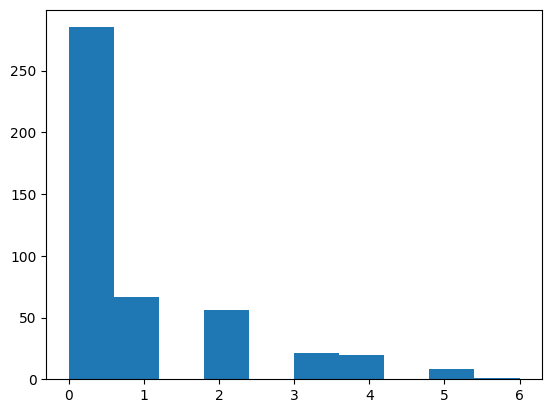

In [174]:
plt.hist(bins[:-1], bins, weights=counts)

In [180]:
counts, bins = np.histogram(
    fh_agg_01.loc[~np.isnan(fh_agg_01.MinYear),'MinYear']
)
counts, bins = np.histogram(
    fh_agg_01.loc[~np.isnan(fh_agg_01.MaxYear),'MaxYear']
)

(array([ 4.,  1., 21., 19.,  7.,  0., 14., 12., 74., 21.]),
 array([1982. , 1986.3, 1990.6, 1994.9, 1999.2, 2003.5, 2007.8, 2012.1,
        2016.4, 2020.7, 2025. ]),
 <BarContainer object of 10 artists>)

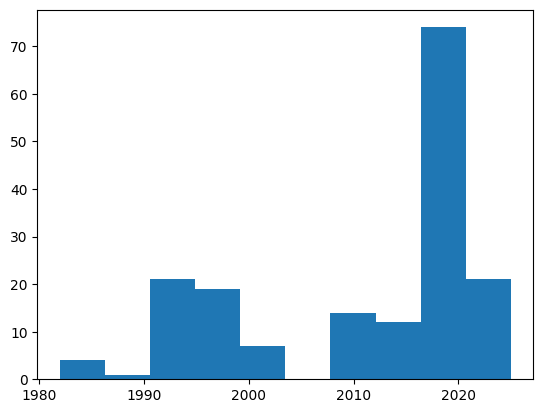

In [181]:
plt.hist(bins[:-1], bins, weights=counts)

In [183]:
fh_ESBS_01.groupby(level=0)[['MinYear',	'MaxYear']].aggregate(lambda x: list(x))

,MinYear,MaxYear
16569,"[2000.0, 2017.0]","[2000.0, 2017.0]"
16570,"[2000.0, 2017.0]","[2000.0, 2017.0]"
16571,[nan],[nan]
16572,[nan],[nan]
16573,[nan],[nan]
...,...,...
38541,"[1995.0, 2016.0]","[1994.0, 2015.0]"
38542,[nan],[nan]
38543,"[2000.0, 1982.0]","[2000.0, 1982.0]"
39603,[nan],[nan]
